In [ ]:
#Install the tools we need: statsbombpy to get foootball data, and mplcoccer to draw the pitch
!pip install statsbombpy mplsoccer

In [ ]:
#Get all free competitions from StatsBomb and find the ID numbers for the 2022 World Cup
from statsbombpy import sb

competitions = sb.competitions()
# keep only the FIFA World Cup rows
wc = competitions[competitions['competition_name'] == 'FIFA World Cup']
print(wc[['competition_name', 'season_name', 'competition_id', 'season_id']])


/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


   competition_name season_name  competition_id  season_id
30   FIFA World Cup        2022              43        106
31   FIFA World Cup        2018              43          3
32   FIFA World Cup        1990              43         55
33   FIFA World Cup        1986              43         54
34   FIFA World Cup        1974              43         51
35   FIFA World Cup        1970              43        272
36   FIFA World Cup        1962              43        270
37   FIFA World Cup        1958              43        269


In [ ]:
# Get all the 2022 World Cup matches
matches = sb.matches(competition_id=43, season_id=106)
# Get only the Argentina matches
argentina = matches[(matches['home_team'] == 'Argentina') | (matches['away_team'] == 'Argentina')]
print(argentina[['match_date', 'home_team', 'away_team','home_score', 'away_score']])


/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


    match_date    home_team     away_team  home_score  away_score
24  2022-12-09  Netherlands     Argentina           2           2
27  2022-12-18    Argentina        France           3           3
30  2022-12-03    Argentina     Australia           2           1
38  2022-11-30       Poland     Argentina           0           2
39  2022-11-26    Argentina        Mexico           2           0
42  2022-12-13    Argentina       Croatia           3           0
56  2022-11-22    Argentina  Saudi Arabia           1           2


In [ ]:
import pandas as pd

all_shots = []
# Go over every Argentina match in the tournoument
for match_id in argentina['match_id']:
  events = sb.events(match_id=match_id)
  shots = events[events['type'] == 'Shot']
  all_shots.append(shots)
# Put all the Argentina players shots in one table
shots = pd.concat(all_shots)
# keep only Messi shots
messi = shots[shots['player'].str.contains('Messi')]

print('Messi shots: ' + str(len(messi)))
print(messi[['minute', 'shot_statsbomb_xg', 'shot_outcome']])

/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: 

Messi shots: 34
      minute  shot_statsbomb_xg shot_outcome
4513      21           0.037833        Off T
4517      39           0.033870        Saved
4518      62           0.076083        Off T
4519      72           0.783500         Goal
4525     109           0.035418        Off T
4531     119           0.042014      Blocked
4534     121           0.783500         Goal
4210      22           0.783500         Goal
4215      59           0.115560        Off T
4224      96           0.043032        Saved
4230     106           0.024785        Saved
4232     107           0.488404         Goal
4238     121           0.783500         Goal
4061      34           0.066638         Goal
4062      49           0.045172        Saved
4064      65           0.032842        Off T
4072      92           0.055600        Off T
4074      93           0.032042      Blocked
4076      94           0.110447      Wayward
3923       6           0.050873        Saved
3925       9           0.053251        

In [ ]:
# Remove the penalty shotout goals because they do not count as an official goals
messi = messi[messi['period'] != 5]
# Count Messi's shots and goals, and add up his total xg
total_shots = len(messi)
goals = len(messi[messi['shot_outcome'] == 'Goal'])
total_xg = messi['shot_statsbomb_xg'].sum()
# Print the results and compare Messi's goals with his xG
print('Shots: ' + str(total_shots))
print('Goals: ' + str(goals))
print('Total xG: ' + str(round(total_xg, 2)))
print('Goals minus xG: ' + str(round(goals - total_xg, 2)))

Shots: 32
Goals: 7
Total xG: 6.03
Goals minus xG: 0.97


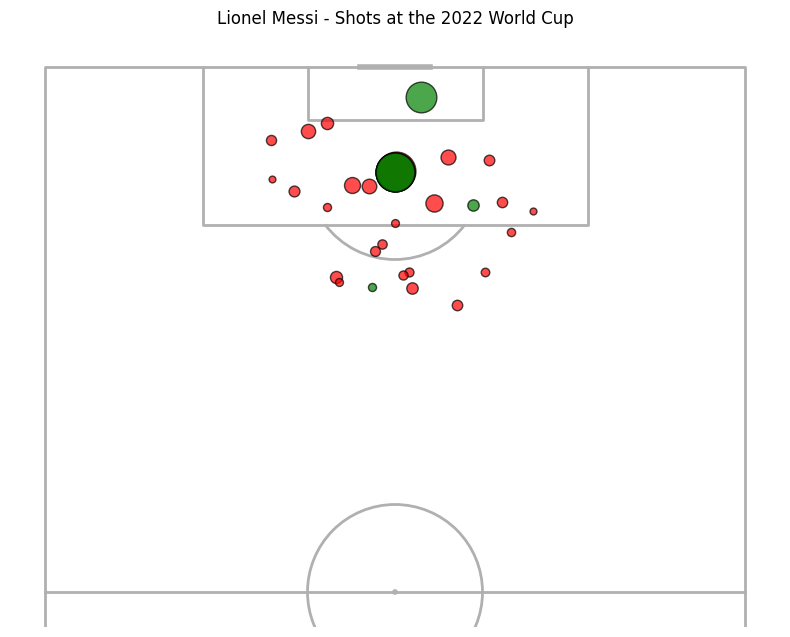

In [ ]:
from mplsoccer import VerticalPitch
import matplotlib.pyplot as plt
# Draw half a football pitch
pitch = VerticalPitch(pitch_type='statsbomb', half=True)
fig, ax = pitch.draw(figsize=(8, 8))
# Go through each Messi's shots and get its location and xG
for i, shot in messi.iterrows():
  x = shot['location'][0]
  y = shot['location'][1]
  xg = shot['shot_statsbomb_xg']
# Green for goals, red for missed shots
  if shot['shot_outcome'] == 'Goal':
    color = 'green'
  else:
    color = 'red'
# Draw each shot= as a dot. A bigger dot means higher xG
  pitch.scatter(x, y, s=xg*1000, color=color, edgecolors='black', alpha=0.7, ax=ax)

ax.set_title('Lionel Messi - Shots at the 2022 World Cup')
plt.show()

These numbers that we see are Messi shots in the world cup. He had 32 shots and scored 7 goals. His total xG was 6.03 which means he scored about 1 goal more than expected. He scored most of his goals inside the penalty box with 4 penalty goals and 1 goal from outside the box.